# Financial News Sentiment and Stock Price Prediction: LSTM + FinBERT

This notebook has two parts that are shown side by side:

1. **Price forecasting:** a PyTorch LSTM trained on 5 years of AAPL daily closing prices, with a 30-day forecast.
2. **Sentiment signals:** 80K+ tweets across 25 stocks, labelled with VADER, classified with TF-IDF + Naive Bayes / Logistic Regression / Random Forest, and scored with FinBERT to produce a Buy / Hold / Sell signal per stock.

**Setup:** put `stock_tweets.csv` in a `data/` folder (see README for the source). All numbers shown below are the saved outputs of the original run.

**Important limitations** are listed at the end of this notebook.

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler


In [ ]:
def get_stock_data(ticker, period="5y"):
    stock = yf.Ticker(ticker)
    # auto_adjust=True returns adjusted close prices
    df = stock.history(period=period, auto_adjust=True)
    df = df[['Close']]
    df.dropna(inplace=True)
    return df

In [ ]:
def preprocess_data(df, sequence_length=50):
    scaler = MinMaxScaler()
    df_scaled = scaler.fit_transform(df[['Close']])  # shape: (num_samples, 1)
    sequences = []
    targets = []
    for i in range(len(df_scaled) - sequence_length):
        sequences.append(df_scaled[i:i+sequence_length])
        targets.append(df_scaled[i+sequence_length, 0])
    return np.array(sequences), np.array(targets), scaler

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, num_layers=2, output_size=1):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])
        return out

In [ ]:
def train_model(model, train_loader, criterion, optimizer, epochs=20):
    model.train()
    for epoch in range(epochs):
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y.view(-1, 1))
            loss.backward()
            optimizer.step()
        print(f"Epoch {epoch+1}, Loss: {loss.item():.4f}")

In [ ]:
def forecast_future(model, recent_data, future_steps=30):
    """
    recent_data: np.array of shape (seq_len, 1) with scaled Close prices
    future_steps: number of future days to forecast
    """
    model.eval()
    predictions = []
    # Shape: (1, seq_len, 1)
    input_seq = torch.tensor(recent_data, dtype=torch.float32).unsqueeze(0)

    with torch.no_grad():
        for _ in range(future_steps):
            # Model outputs a single prediction with shape (1, 1)
            pred = model(input_seq)
            predictions.append(pred.item())
            # Remove the first timestep and append the new prediction at the end.
            # pred.unsqueeze(1) converts shape from (1, 1) to (1, 1, 1)
            input_seq = torch.cat((input_seq[:, 1:, :], pred.unsqueeze(1)), dim=1)

    return predictions


Head of stock data:
                                Close
Date                                
2020-02-25 00:00:00-05:00  69.910980
2020-02-26 00:00:00-05:00  71.020004
2020-02-27 00:00:00-05:00  66.377556
2020-02-28 00:00:00-05:00  66.338737
2020-03-02 00:00:00-05:00  72.514923
Tail of stock data:
                                 Close
Date                                 
2025-02-18 00:00:00-05:00  244.470001
2025-02-19 00:00:00-05:00  244.869995
2025-02-20 00:00:00-05:00  245.830002
2025-02-21 00:00:00-05:00  245.550003
2025-02-24 00:00:00-05:00  247.100006
Epoch 1, Loss: 0.0258
Epoch 2, Loss: 0.0067
Epoch 3, Loss: 0.0009
Epoch 4, Loss: 0.0009
Epoch 5, Loss: 0.0006
Epoch 6, Loss: 0.0012
Epoch 7, Loss: 0.0006
Epoch 8, Loss: 0.0010
Epoch 9, Loss: 0.0008
Epoch 10, Loss: 0.0006
Scaled predictions (30 days): [0.9147966504096985, 0.9185261726379395, 0.92127525806427, 0.9234482645988464, 0.9252813458442688, 0.9269160628318787, 0.9284360408782959, 0.9298890233039856, 0.9313021302223206, 0.9

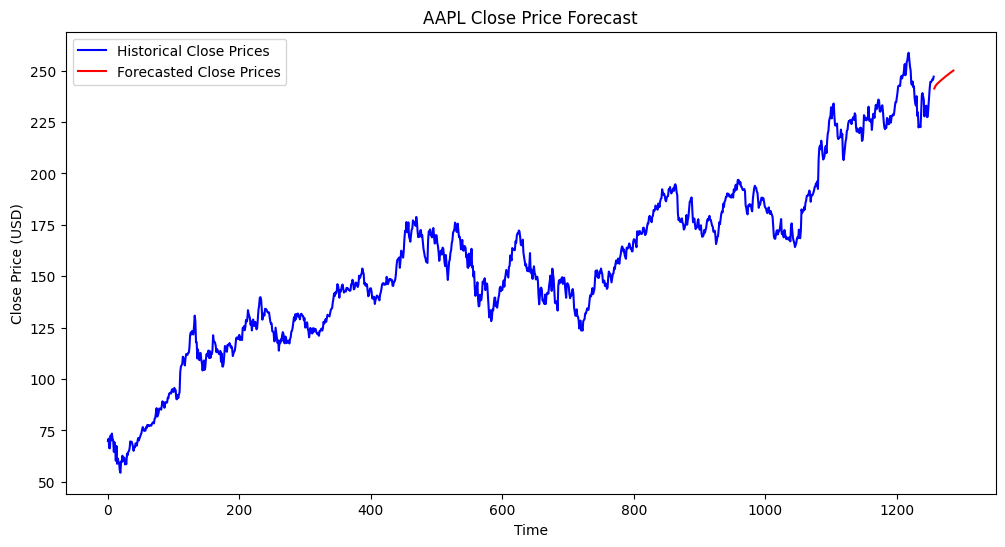

In [ ]:
if __name__ == "__main__":
    ticker = "AAPL"  # Apple Inc.

    # (A) Get historical data (using auto_adjust for adjusted Close prices)
    stock_data = get_stock_data(ticker, period="5y")
    print("Head of stock data:\n", stock_data.head())
    print("Tail of stock data:\n", stock_data.tail())

    # (B) Preprocess the data (using only Close price)
    sequence_length = 50
    sequences, targets, scaler = preprocess_data(stock_data, sequence_length=sequence_length)

    # (C) Create PyTorch DataLoader for training
    train_x = torch.tensor(sequences, dtype=torch.float32)
    train_y = torch.tensor(targets, dtype=torch.float32)
    train_loader = torch.utils.data.DataLoader(list(zip(train_x, train_y)), batch_size=32, shuffle=True)

    # (D) Initialize the model, loss, and optimizer
    model = LSTMModel(input_size=1, hidden_size=50, num_layers=2, output_size=1)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # (E) Train the model
    train_model(model, train_loader, criterion, optimizer, epochs=10)

    # (F) Forecast the next 30 days using the last sequence in the training set
    future_scaled = forecast_future(model, sequences[-1], future_steps=30)
    print("Scaled predictions (30 days):", future_scaled)

    # (G) Convert the final forecast to USD (inverse transformation)
    forecast_30_scaled = future_scaled[-1]
    forecast_30_usd = scaler.inverse_transform(np.array([[forecast_30_scaled]]))[0, 0]
    print("Predicted AAPL Close after 30 days (USD):", forecast_30_usd)

    # (H) Plot Historical vs. Forecasted Prices
    historical_prices = stock_data['Close'].values  # original Close prices in USD
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(historical_prices)), historical_prices, label="Historical Close Prices", color="blue")

    # Inverse transform the forecasted scaled values to USD
    future_scaled_arr = np.array(future_scaled).reshape(-1, 1)
    future_unscaled = scaler.inverse_transform(future_scaled_arr)

    # Plot forecast starting after the last known data point
    plt.plot(range(len(historical_prices), len(historical_prices) + len(future_unscaled)),
             future_unscaled, label="Forecasted Close Prices", color="red")

    plt.xlabel("Time")
    plt.ylabel("Close Price (USD)")
    plt.title(f"AAPL Close Price Forecast")
    plt.legend()
    plt.show()


### Backtest (in-sample, for illustration only)
The strategy goes long when the model predicts a higher next-day close, otherwise stays in cash. It is evaluated on the **same data the model was trained on**, with no transaction costs, so it is **not** evidence of a tradable edge. In this run it returned **113.57%** versus **242.19%** for buy-and-hold.

In [ ]:
def backtest_strategy(model, sequences, targets, scaler):
    """
    For each training sample:
      - Use the input sequence (of scaled Close prices)
      - Predict the next day’s scaled Close price.
      - Inverse transform the last day of the sequence and the prediction.
      - Generate a signal: if predicted price > last actual price, signal = 1 (long); else 0.
      - Compute the daily return (if you held the stock from the last day to the target day).
    Then, compute the cumulative return of the strategy versus a buy-and-hold strategy.
    """
    strategy_returns = []
    buy_hold_returns = []

    # Loop over all samples in the training set (each corresponds to a day)
    for i in range(len(targets)):
        seq = sequences[i]            # shape: (sequence_length, 1)
        last_scaled = seq[-1, 0]       # last day's scaled close in the sequence
        last_actual = scaler.inverse_transform([[last_scaled]])[0, 0]

        # Predict the next day's scaled close using the model
        seq_tensor = torch.tensor(seq, dtype=torch.float32).unsqueeze(0)
        pred_scaled = model(seq_tensor).item()
        pred_actual = scaler.inverse_transform([[pred_scaled]])[0, 0]

        # Actual target price (next day's close)
        target_scaled = targets[i]
        target_actual = scaler.inverse_transform([[target_scaled]])[0, 0]

        # Compute the daily return if holding from last day of the sequence to the target day
        daily_return = target_actual / last_actual - 1

        # Trading signal: long if predicted price > last day's price, else stay in cash
        signal = 1 if pred_actual > last_actual else 0

        strategy_returns.append(signal * daily_return)
        buy_hold_returns.append(daily_return)

    strategy_returns = np.array(strategy_returns)
    buy_hold_returns = np.array(buy_hold_returns)

    # Compute cumulative returns (assuming you reinvest gains each day)
    cum_strategy = np.cumprod(1 + strategy_returns) - 1
    cum_buy_hold = np.cumprod(1 + buy_hold_returns) - 1

    # Performance metrics:
    print("Final Strategy Cumulative Return over 5yrs: {:.2f}%".format(cum_strategy[-1]*100))
    print("Final Buy & Hold Cumulative Return over 5yrs: {:.2f}%".format(cum_buy_hold[-1]*100))

    # Plot cumulative returns over time
    plt.figure(figsize=(12,6))
    plt.plot(cum_strategy, label="Strategy Cumulative Return", color="green")
    plt.plot(cum_buy_hold, label="Buy & Hold Cumulative Return", color="orange")
    plt.xlabel("Time Index")
    plt.ylabel("Cumulative Return")
    plt.title("Backtesting: Strategy vs. Buy & Hold")
    plt.legend()
    plt.show()

    return cum_strategy, cum_buy_hold


Final Strategy Cumulative Return over 5yrs: 113.57%
Final Buy & Hold Cumulative Return over 5yrs: 242.19%


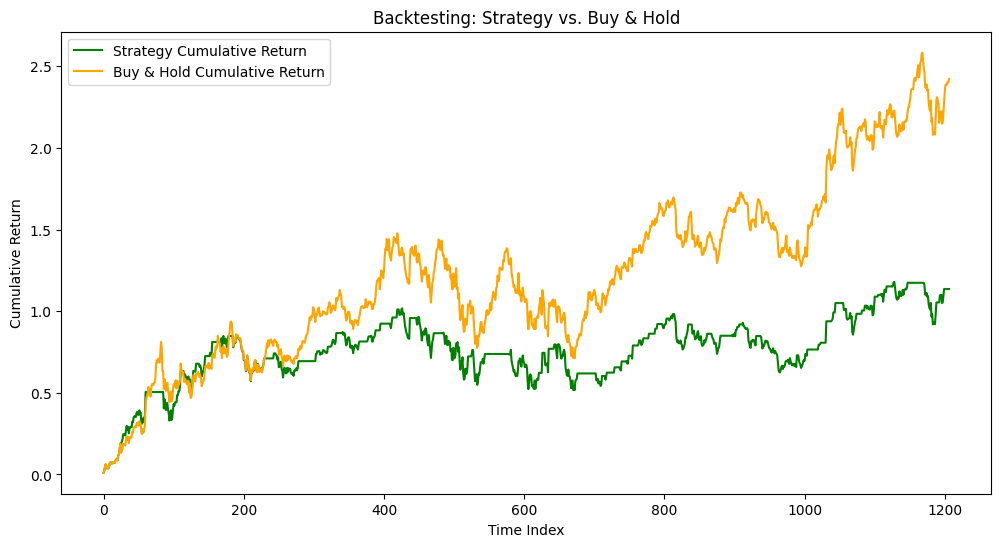

(array([0.01031716, 0.02076881, 0.04506517, ..., 1.13569499, 1.13569499,
        1.13569499]),
 array([0.01031716, 0.02076881, 0.04506517, ..., 2.40430246, 2.40042498,
        2.42188973]))

In [ ]:
backtest_strategy(model, sequences, targets, scaler)

# Part 2: Sentiment signals from financial tweets (VADER labels, classical ML, FinBERT)


In [ ]:
import numpy as np
import re
import string
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [ ]:
nltk.download('vader_lexicon')
nltk.download('stopwords')
nltk.download('punkt')


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [ ]:
df = pd.read_csv("data/stock_tweets.csv")

In [ ]:
df.head()

,Date,Tweet,Stock Name,Company Name
0,2022-09-29 23:41:16+00:00,Mainstream media has done an amazing job at br...,TSLA,"Tesla, Inc."
1,2022-09-29 23:24:43+00:00,Tesla delivery estimates are at around 364k fr...,TSLA,"Tesla, Inc."
2,2022-09-29 23:18:08+00:00,3/ Even if I include 63.0M unvested RSUs as of...,TSLA,"Tesla, Inc."
3,2022-09-29 22:40:07+00:00,@RealDanODowd @WholeMarsBlog @Tesla Hahaha why...,TSLA,"Tesla, Inc."
4,2022-09-29 22:27:05+00:00,"@RealDanODowd @Tesla Stop trying to kill kids,...",TSLA,"Tesla, Inc."


In [ ]:
def clean_text(text):
    text = text.lower()  # Convert to lowercase
    text = re.sub(r"http\S+|www\S+|https\S+", '', text, flags=re.MULTILINE)  # Remove URLs
    text = re.sub(r'@\w+|\#', '', text)  # Remove mentions and hashtags
    text = text.translate(str.maketrans('', '', string.punctuation))  # Remove punctuation
    text = re.sub(r'\d+', '', text)  # Remove numbers
    text = re.sub(r'\s+', ' ', text).strip()  # Remove extra spaces
    return text

In [ ]:
df['Cleaned_Tweet'] = df['Tweet'].apply(clean_text)

In [ ]:
df.head()

,Date,Tweet,Stock Name,Company Name,Cleaned_Tweet
0,2022-09-29 23:41:16+00:00,Mainstream media has done an amazing job at br...,TSLA,"Tesla, Inc.",mainstream media has done an amazing job at br...
1,2022-09-29 23:24:43+00:00,Tesla delivery estimates are at around 364k fr...,TSLA,"Tesla, Inc.",tesla delivery estimates are at around k from ...
2,2022-09-29 23:18:08+00:00,3/ Even if I include 63.0M unvested RSUs as of...,TSLA,"Tesla, Inc.",even if i include m unvested rsus as of additi...
3,2022-09-29 22:40:07+00:00,@RealDanODowd @WholeMarsBlog @Tesla Hahaha why...,TSLA,"Tesla, Inc.",hahaha why are you still trying to stop tesla ...
4,2022-09-29 22:27:05+00:00,"@RealDanODowd @Tesla Stop trying to kill kids,...",TSLA,"Tesla, Inc.",stop trying to kill kids you sad deranged old man


In [ ]:
sia = SentimentIntensityAnalyzer()

In [ ]:
def get_sentiment(text):
    score = sia.polarity_scores(text)['compound']
    if score >= 0.05:
        return 1  # Positive
    elif score <= -0.05:
        return -1  # Negative
    else:
        return 0  # Neutral

df['Sentimental_Analysis'] = df['Cleaned_Tweet'].apply(get_sentiment)

In [ ]:
X = df['Cleaned_Tweet']
y = df['Sentimental_Analysis']


In [ ]:
vectorizer = TfidfVectorizer(max_features=5000)
X_tfidf = vectorizer.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

In [ ]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier(n_estimators=100)
}

for name, clf in models.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    print(f"Model: {name}")
    print(classification_report(y_test, y_pred))

Model: Naive Bayes
              precision    recall  f1-score   support

          -1       0.86      0.38      0.52      3251
           0       0.84      0.49      0.62      4807
           1       0.65      0.96      0.77      8101

    accuracy                           0.70     16159
   macro avg       0.78      0.61      0.64     16159
weighted avg       0.75      0.70      0.68     16159

Model: Logistic Regression
              precision    recall  f1-score   support

          -1       0.85      0.69      0.76      3251
           0       0.85      0.91      0.88      4807
           1       0.89      0.92      0.91      8101

    accuracy                           0.87     16159
   macro avg       0.86      0.84      0.85     16159
weighted avg       0.87      0.87      0.87     16159

Model: Random Forest
              precision    recall  f1-score   support

          -1       0.93      0.43      0.59      3251
           0       0.81      0.82      0.81      4807
        

In [ ]:
df.to_csv("data/tweets_with_sentiment.csv", index=False)

In [ ]:
df2 = pd.read_csv("data/tweets_with_sentiment.csv")

In [ ]:
df2.head()

,Date,Tweet,Stock Name,Company Name,Cleaned_Tweet,Sentimental_Analysis
0,2022-09-29 23:41:16+00:00,Mainstream media has done an amazing job at br...,TSLA,"Tesla, Inc.",mainstream media has done an amazing job at br...,1
1,2022-09-29 23:24:43+00:00,Tesla delivery estimates are at around 364k fr...,TSLA,"Tesla, Inc.",tesla delivery estimates are at around k from ...,0
2,2022-09-29 23:18:08+00:00,3/ Even if I include 63.0M unvested RSUs as of...,TSLA,"Tesla, Inc.",even if i include m unvested rsus as of additi...,1
3,2022-09-29 22:40:07+00:00,@RealDanODowd @WholeMarsBlog @Tesla Hahaha why...,TSLA,"Tesla, Inc.",hahaha why are you still trying to stop tesla ...,-1
4,2022-09-29 22:27:05+00:00,"@RealDanODowd @Tesla Stop trying to kill kids,...",TSLA,"Tesla, Inc.",stop trying to kill kids you sad deranged old man,-1


In [ ]:
df2.describe()

,Sentimental_Analysis
count,80793.000000
mean,0.308133
std,0.780810
min,-1.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


In [ ]:
df2.columns

Index(['Date', 'Tweet', 'Stock Name', 'Company Name', 'Cleaned_Tweet',
       'Sentimental_Analysis'],
      dtype='object')

In [ ]:
df2["Stock Name"].unique()

array(['TSLA', 'MSFT', 'PG', 'META', 'AMZN', 'GOOG', 'AMD', 'AAPL',
       'NFLX', 'TSM', 'KO', 'F', 'COST', 'DIS', 'VZ', 'CRM', 'INTC', 'BA',
       'BX', 'NOC', 'PYPL', 'ENPH', 'NIO', 'ZS', 'XPEV'], dtype=object)

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

# Load pre-trained model and tokenizer
model_name = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

def predict_sentiment(text):
    inputs = tokenizer(text, return_tensors="pt")
    outputs = model(**inputs)
    predicted_class = torch.argmax(outputs.logits).item()
    # FinBERT's labels: 0: neutral, 1: positive, 2: negative
    if predicted_class == 1:
        return "Buy"  # Positive sentiment suggests buying
    elif predicted_class == 2:
        return "Sell"  # Negative sentiment suggests selling
    else:
        return "Hold" # Neutral sentiment suggests holding


def get_stock_prediction(stock_name):
    # Filter tweets for the specific stock
    stock_tweets = df2[df2["Stock Name"] == stock_name]

    if stock_tweets.empty:
      return f"No tweets found for {stock_name}"

    # Analyze the sentiment of each tweet
    predictions = []
    for tweet in stock_tweets["Cleaned_Tweet"]:
        predictions.append(predict_sentiment(tweet))

    # Determine overall recommendation (could be improved with more sophisticated aggregation)
    buy_count = predictions.count("Buy")
    sell_count = predictions.count("Sell")
    hold_count = predictions.count("Hold")

    if buy_count > sell_count and buy_count > hold_count:
        return f"Recommendation for {stock_name}: Buy"
    elif sell_count > buy_count and sell_count > hold_count:
        return f"Recommendation for {stock_name}: Sell"
    else:
        return f"Recommendation for {stock_name}: Hold"

# Example usage:
stock_name = "AAPL"  # Replace with desired stock name
print(get_stock_prediction(stock_name))

Recommendation for AAPL: Sell


### Risk summary for the 30-day AAPL forecast (uses the Part 1 forecast above)
These are rough estimates derived from the forecast path itself (volatility, a simple confidence interval and an approximate Sharpe ratio), not a validated risk model.

In [ ]:
# (G) Convert the final forecast to USD (inverse transformation)
forecast_30_scaled = future_scaled[-1]
forecast_30_usd = scaler.inverse_transform(np.array([[forecast_30_scaled]]))[0, 0]

# Get the last actual closing price
last_actual_price = stock_data['Close'].values[-1]

# Calculate expected percentage change
percentage_change = ((forecast_30_usd - last_actual_price) / last_actual_price) * 100

print(f"Predicted AAPL Close after 30 days (USD): {forecast_30_usd:.2f}")
print(f"Expected Percentage Change in Stock Price: {percentage_change:.2f}%")


Predicted AAPL Close after 30 days (USD): 250.06
Expected Percentage Change in Stock Price: 1.20%


In [ ]:
# Compute volatility (std deviation of predicted future prices)
future_unscaled = scaler.inverse_transform(np.array(future_scaled).reshape(-1, 1))
forecast_volatility = np.std(future_unscaled)

print(f"Expected Volatility (Standard Deviation of Forecasted Prices): {forecast_volatility:.2f} USD")


Expected Volatility (Standard Deviation of Forecasted Prices): 2.43 USD


In [ ]:
confidence_interval = 1.96 * forecast_volatility / np.sqrt(30)
lower_bound = forecast_30_usd - confidence_interval
upper_bound = forecast_30_usd + confidence_interval

print(f"Predicted 30-day Close Price Range: {lower_bound:.2f} - {upper_bound:.2f} USD (95% CI)")


Predicted 30-day Close Price Range: 249.19 - 250.93 USD (95% CI)


In [ ]:
risk_free_rate = 0.05 / 252  # Assuming 5% annual risk-free rate, divided by 252 trading days
expected_daily_growth = percentage_change/30
excess_return = expected_daily_growth - risk_free_rate
sharpe_ratio = excess_return / forecast_volatility if forecast_volatility != 0 else 0

print(f"Approximate Sharpe Ratio: {sharpe_ratio:.4f}")


Approximate Sharpe Ratio: 0.0164


In [ ]:
if percentage_change > 5:
    trend = "Strong Bullish Trend 📈"
elif percentage_change > 0:
    trend = "Mild Bullish Trend ✅"
elif percentage_change < -5:
    trend = "Strong Bearish Trend 📉"
else:
    trend = "Neutral / Sideways Market 🔄"

print(f"Trend Classification: {trend}")


Trend Classification: Mild Bullish Trend ✅


In [ ]:
print(f"Predicted AAPL Close after 30 days (USD): {forecast_30_usd:.2f}")
print(f"Expected Percentage Change in Stock Price: {percentage_change:.2f}%")
print(f"Expected Volatility (Standard Deviation of Forecasted Prices): {forecast_volatility:.2f} USD")
print(f"Predicted 30-day Close Price Range: {lower_bound:.2f} - {upper_bound:.2f} USD (95% CI)")
print(f"Approximate Sharpe Ratio: {sharpe_ratio:.4f}")
print(f"Trend Classification: {trend}")

Predicted AAPL Close after 30 days (USD): 250.06
Expected Percentage Change in Stock Price: 1.20%
Expected Volatility (Standard Deviation of Forecasted Prices): 2.43 USD
Predicted 30-day Close Price Range: 249.19 - 250.93 USD (95% CI)
Approximate Sharpe Ratio: 0.0164
Trend Classification: Mild Bullish Trend ✅


## Limitations
- **Labels come from VADER, not humans.** The 0.87 accuracy / 0.85 macro-F1 for Logistic Regression measures agreement with VADER's labels on 16,159 held-out tweets.
- **The two parts are not fused into one model.** The LSTM forecast and the FinBERT signal are produced independently. For AAPL they disagree here (LSTM: mild bullish, +1.20% in 30 days; FinBERT majority vote: Sell).
- **The LSTM uses only closing prices** (single feature), recursive multi-step forecasting, and a 10-epoch run; there is no train/validation/test split by time.
- **The backtest is in-sample** and ignores costs and slippage.
- **The Sharpe ratio and confidence interval are approximations.**
- This is a learning project and **not financial advice**.

## Possible next steps
- Time-based train/validation/test split and walk-forward evaluation.
- Fuse sentiment features into the LSTM and test whether they improve out-of-sample error.
- Human-labelled or finance-specific evaluation set for the sentiment models.